# Lab Assignment 8 – NLP & Topic Modelling on Health-Related Headlines

In [1]:
!pip install -q pyLDAvis wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 73.9 MB/s eta 0:00:00


In [2]:
import os, re, glob, string, subprocess
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

## Task 1: Data Preprocessing and Cleaning
### Load the dataset

In [3]:
# The PDF's URL lost a hyphen at a line break, so try both spellings.
REPO_URLS = [
    "https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing",
    "https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-forNatural-Language-Processing",
]
REPO_DIR = "/content/health_headlines"

if not os.path.isdir(REPO_DIR):
    for url in REPO_URLS:
        r = subprocess.run(["git", "clone", "--depth", "1", url, REPO_DIR],
                           capture_output=True, text=True,
                           env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
        if r.returncode == 0:
            print("Cloned:", url); break
    else:
        print("Clone failed. Download the repo ZIP manually and upload it (next cell).")

files = [f for f in glob.glob(f"{REPO_DIR}/**/*", recursive=True)
         if f.lower().endswith((".csv", ".json", ".xlsx", ".xls", ".tsv"))]
for f in files:
    print(f"{os.path.getsize(f)/1024:9.1f} KB  {f}")

Cloned: https://github.com/WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing
    721.4 KB  /content/health_headlines/Substance_Abuse_and_Addiction_News_Headlines.csv
    695.0 KB  /content/health_headlines/Substance_Abuse_and_Addiction_Journals_Headlines.csv
    333.3 KB  /content/health_headlines/Clinical_Trials_Perspective_Headlines.csv
    930.9 KB  /content/health_headlines/Pain_Management_News_Headlines.csv
    380.6 KB  /content/health_headlines/Adult_Immunization_News_Headlines.csv
     81.0 KB  /content/health_headlines/Antibiotic_Resistance_Perspective_Headlines.csv
    651.5 KB  /content/health_headlines/Adverse_Drug_Reaction_News_Headlines.csv
   2265.7 KB  /content/health_headlines/Clinical_Trials_Related_Headlines.csv
    268.0 KB  /content/health_headlines/Patient_Safety_Perspective_Headlines.csv
    675.8 KB  /content/health_headlines/Immunization_Related_Headlines.csv
    102.9 KB  /content/health_headlines/Antibiotic_Resistance_News_Headl

In [5]:
# ---- CONFIG: set these after looking at the file list above ----
DATA_FILE = None      # e.g. "/content/health_headlines/<file>.csv"; None = largest file found
TEXT_COL  = None      # e.g. "Headline"; None = auto-pick the column with longest average text

def load_any(path):
    p = path.lower()
    if p.endswith(".csv"):  return pd.read_csv(path, encoding_errors="replace", on_bad_lines="skip")
    if p.endswith(".tsv"):  return pd.read_csv(path, sep="\t", encoding_errors="replace", on_bad_lines="skip")
    if p.endswith(".json"):
        try:    return pd.read_json(path)
        except ValueError: return pd.read_json(path, lines=True)
    return pd.read_excel(path)

if DATA_FILE is None:
    DATA_FILE = max(files, key=os.path.getsize)
df = load_any(DATA_FILE)
print("Using:", DATA_FILE, "| shape:", df.shape)
print(df.dtypes)

if TEXT_COL is None:
    obj_cols = df.select_dtypes(include="object").columns
    TEXT_COL = max(obj_cols, key=lambda c: df[c].astype(str).str.len().mean())
print("Text column:", TEXT_COL)

df = df[[TEXT_COL]].dropna().drop_duplicates().rename(columns={TEXT_COL: "raw_text"}).reset_index(drop=True)
df["raw_text"] = df["raw_text"].astype(str)
print("Rows after dropping NaN/duplicates:", len(df))
df.head()

Using: /content/health_headlines/Health_Related_Headlines_Dataset.csv | shape: (39405, 5)
Date         object
Source       object
Headlines    object
Teaser       object
Category     object
dtype: object
Text column: Teaser
Rows after dropping NaN/duplicates: 31164


,raw_text
0,New recommendations for already approved vacci...
1,"In a randomized trial, combined Internet and t..."
2,It is proposed that depressed children identif...
3,The epidemic of heroin abuse within the US has...
4,A small study using one variety of magnet for ...


### Lowercasing, punctuation removal, tokenization, stop-word removal, lemmatization

In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()                                              # lowercasing
    text = re.sub(r"http\S+|www\.\S+", " ", text)                    # URLs
    text = text.translate(str.maketrans("", "", string.punctuation)) # punctuation removal
    text = re.sub(r"[^a-z\s]", " ", text)                            # digits / odd symbols
    tokens = word_tokenize(text)                                     # tokenization
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]  # stop-words
    tokens = [lemmatizer.lemmatize(t) for t in tokens]               # lemmatization
    return tokens

df["tokens"] = df["raw_text"].apply(clean_text)
df["clean_text"] = df["tokens"].apply(" ".join)
df = df[df["tokens"].str.len() > 0].reset_index(drop=True)

for i in range(5):
    print("RAW  :", df.raw_text[i])
    print("CLEAN:", df.clean_text[i], "\n")

RAW  : New recommendations for already approved vaccines and a newly approved vaccine for meningococcal B infections -- what you need to know.
CLEAN: new recommendation already approved vaccine newly approved vaccine meningococcal infection need know 

RAW  : In a randomized trial, combined Internet and telephone treatment of smoking cessation outperformed static and dynamic Internet interventions.
CLEAN: randomized trial combined internet telephone treatment smoking cessation outperformed static dynamic internet intervention 

RAW  : It is proposed that depressed children identify families with a specific form of bipolar disorder similar to alcoholism.
CLEAN: proposed depressed child identify family specific form bipolar disorder similar alcoholism 

RAW  : The epidemic of heroin abuse within the US has produced an influx of addicts requiring effective opioid substitution.
CLEAN: epidemic heroin abuse within produced influx addict requiring effective opioid substitution 

RAW  : A sma

## Task 2: Exploratory Text Analysis & Word Visualization

In [7]:
all_tokens = [t for toks in df["tokens"] for t in toks]
freq = Counter(all_tokens)
print("Total tokens:", len(all_tokens), "| Vocabulary size:", len(freq))
freq_df = pd.DataFrame(freq.most_common(), columns=["word", "count"])
freq_df.head(20)

Total tokens: 428124 | Vocabulary size: 25800


,word,count
0,patient,7793
1,study,5050
2,new,4847
3,risk,3747
4,treatment,3177
5,drug,2840
6,may,2631
7,pain,2618
8,use,2542
9,cancer,2539


/tmp/ipykernel_2296/3103082271.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top20, x="count", y="word", palette="viridis")


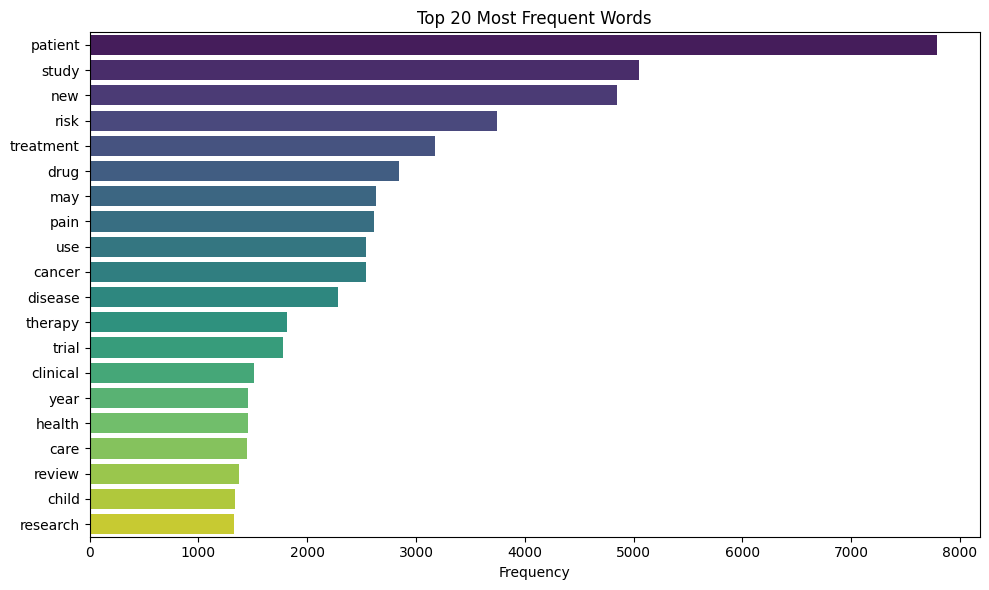

In [8]:
top20 = freq_df.head(20)
plt.figure(figsize=(10, 6))
sns.barplot(data=top20, x="count", y="word", palette="viridis")
plt.title("Top 20 Most Frequent Words"); plt.xlabel("Frequency"); plt.ylabel("")
plt.tight_layout(); plt.show()

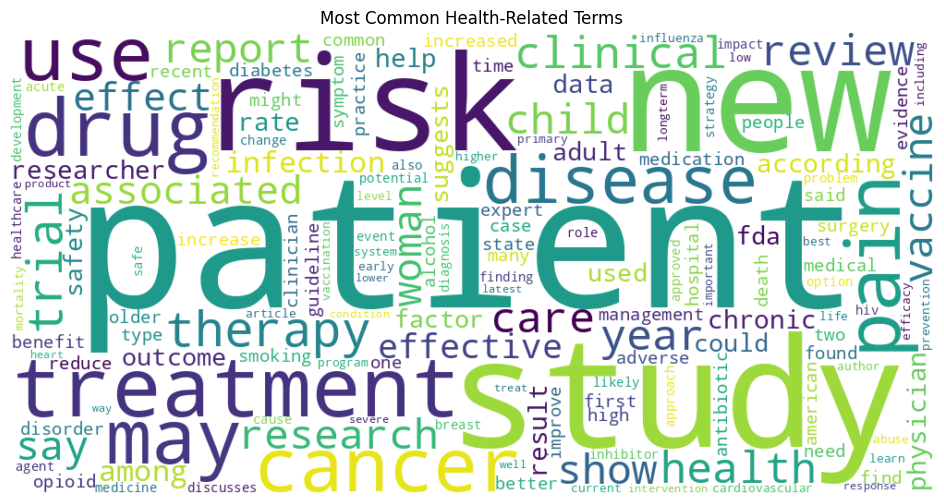

In [9]:
wc = WordCloud(width=1000, height=500, background_color="white", max_words=150, colormap="viridis")
wc = wc.generate_from_frequencies(freq)
plt.figure(figsize=(12, 6)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("Most Common Health-Related Terms"); plt.show()

## Task 3: Topic Modelling using LDA

In [10]:
N_TOPICS = 5
vectorizer = CountVectorizer(max_df=0.5, min_df=5)   # drop ubiquitous and very rare terms
dtm = vectorizer.fit_transform(df["clean_text"])
print("Document-term matrix:", dtm.shape)

lda = LatentDirichletAllocation(n_components=N_TOPICS, learning_method="batch",
                                max_iter=20, random_state=42, n_jobs=-1)
lda.fit(dtm)

vocab = vectorizer.get_feature_names_out()
for idx, comp in enumerate(lda.components_):
    top_words = [vocab[i] for i in comp.argsort()[::-1][:5]]
    print(f"Topic {idx+1}: {', '.join(top_words)}")

Document-term matrix: (31163, 7438)
Topic 1: patient, pain, treatment, effective, study
Topic 2: vaccine, health, new, care, year
Topic 3: patient, physician, say, medical, hospital
Topic 4: risk, study, patient, new, may
Topic 5: cancer, drug, patient, treatment, trial


In [11]:
# Dominant topic per document + topic share
doc_topics = lda.transform(dtm)
df["dominant_topic"] = doc_topics.argmax(axis=1) + 1
print(df["dominant_topic"].value_counts().sort_index())
df[["raw_text", "dominant_topic"]].sample(8, random_state=1)

dominant_topic
1    7481
2    6178
3    4917
4    8379
5    4208
Name: count, dtype: int64


,raw_text,dominant_topic
2085,Biogen Idec and Elan reported to the SEC that ...,1
28105,With Canada about to legalize marijuana on Wed...,3
29698,"For one patient, a three-month supply of insul...",3
15151,Music is an intriguing intervention with poten...,3
1455,Europe has approved 2 new indications for sita...,5
25262,"In a session on decision-making, bias, and med...",3
16375,Attendees at an obesity session at the AACE an...,2
292,Risk of deep vein thrombosis and pulmonary com...,1


In [12]:
import pyLDAvis
try:
    import pyLDAvis.lda_model as ldavis_module     # pyLDAvis >= 3.4
except ImportError:
    import pyLDAvis.sklearn as ldavis_module       # older versions

pyLDAvis.enable_notebook()
panel = ldavis_module.prepare(lda, dtm, vectorizer, mds="tsne")
pyLDAvis.save_html(panel, "lda_visualization.html")   # keep a copy for your report
panel

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PreparedData(topic_coordinates=               x          y  topics  cluster       Freq
topic                                                  
3     -10.028486  24.180210       1        1  26.080408
0     -68.510223   2.860152       2        1  21.506808
1      13.694744 -76.416176       3        1  19.960135
2      33.447411 -17.341961       4        1  17.143477
4     -40.796116 -50.639202       5        1  15.309172, topic_info=            Term         Freq        Total Category  logprob  loglift
957       cancer  2548.000000  2548.000000  Default  30.0000  30.0000
4767        pain  2552.000000  2552.000000  Default  29.0000  29.0000
5850        risk  3641.000000  3641.000000  Default  28.0000  28.0000
7122     vaccine  1236.000000  1236.000000  Default  27.0000  27.0000
2048        drug  2821.000000  2821.000000  Default  26.0000  26.0000
...          ...          ...          ...      ...      ...      ...
4030         may   338.958944  2576.410441   Topic5  -5.1946  -0.1516
1925     disease   314.053577  2230.570051   Topic5  -5.2709  -0.0837
5938         say   277.612814  1247.613432   Topic5  -5.3942   0.3740
5730  researcher   263.329358  1073.911377   Topic5  -5.4470   0.4711
7097         use   275.655870  2489.244184   Topic5  -5.4013  -0.3239

[356 rows x 6 columns], token_table=      Topic      Freq       Term
term                            
15        2  0.986022   ablation
38        3  0.989566    academy
59        1  0.502206  according
59        2  0.099107  according
59        3  0.204885  according
...     ...       ...        ...
7412      3  0.459351       year
7412      4  0.154286       year
7412      5  0.089766       year
7414      2  0.918991    yearold
7414      4  0.076095    yearold

[608 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[4, 1, 2, 3, 5])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
